# Project 2: Result and Error Analysis

This notebook compares the best Project 2 recurrent model (**LSTM + InferSent**) with the best Project 1 model (**logistic regression + overlap features**) on the same 50,000-example MNLI subset and five-fold split.


In [24]:
from pathlib import Path
import sys
import hashlib
from urllib.error import URLError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

sys.path.insert(0, '..')
from pipeline.data import load_saved_folds
from pipeline.embeddings import download_pretrained, PretrainedEmbeddings
from pipeline.tokenization import BasicTokenizer

ROOT = Path('..').resolve()
PART2_ROOT = ROOT / 'results copy' / 'part2'
PART1_ROOT = ROOT / 'results proj 1'
DATA_DIR = ROOT / 'results' / 'data' / 'mnli-n50000-seed0'
OUTPUT_DIR = ROOT / 'results' / 'analysis'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = ['entailment', 'neutral', 'contradiction']
NEGATION_TOKENS = {'not','never','no','nobody','nothing','neither','nor','cannot',"n't"}

subset, folds = load_saved_folds(DATA_DIR)
print(f'MNLI subset: {len(subset)} examples; folds: {sorted(folds)}')

MNLI subset: 50001 examples; folds: [0, 1, 2, 3, 4]


In [25]:
def pair_key(row):
    text = '\\n'.join([str(row['premise']), str(row['hypothesis']), str(row['gold_label'])])
    return hashlib.sha1(text.encode('utf-8')).hexdigest()[:16]


def fold_validation_rows(fold_id):
    return subset.select(folds[fold_id]['validation_ids'])


def load_lstm_predictions(seeds=(0, 100, 200)):
    frames = []
    root = PART2_ROOT / 'final' / 'lstm-frozen-h50-infersent'
    for seed in seeds:
        for fold_id in sorted(folds):
            path = root / f'seed-{seed}' / 'lstm' / f'fold-{fold_id}' / 'predictions.csv'
            if not path.is_file():
                raise FileNotFoundError(path)
            prediction = pd.read_csv(path)
            validation = fold_validation_rows(fold_id)
            if len(prediction) != len(validation):
                raise RuntimeError(f'Length mismatch: seed {seed}, fold {fold_id}')
            prediction = prediction.copy()
            prediction['seed'] = seed
            prediction['fold'] = fold_id
            prediction['premise'] = validation['premise'][:]
            prediction['hypothesis'] = validation['hypothesis'][:]
            prediction['pair_key'] = prediction.apply(pair_key, axis=1)
            prediction['lstm_wrong'] = prediction['gold_label'] != prediction['prediction']
            frames.append(prediction)
    return pd.concat(frames, ignore_index=True)

lstm = load_lstm_predictions()
print(lstm.shape)
lstm.head()

seed0 = lstm[lstm['seed'] == 0].copy()


(150003, 13)


## 1. Main results

Accuracy and macro-F1 are reported as mean ± standard deviation across five validation folds.


In [26]:
model_specs = {
    "Majority": PART2_ROOT / "final" / "majority" / "seed-0" / "fold_scores.csv",
    "Mean pooling + concatenation": PART2_ROOT / "final" / "pool-frozen-concat" / "seed-0" / "fold_scores.csv",
    "Mean pooling + InferSent": PART2_ROOT / "final" / "pool-frozen-infersent" / "seed-0" / "fold_scores.csv",
    "LSTM + concatenation": PART2_ROOT / "final" / "lstm-frozen-h50-concat" / "seed-0" / "fold_scores.csv",
    "LSTM + InferSent": PART2_ROOT / "final" / "lstm-frozen-h50-infersent" / "seed-0" / "fold_scores.csv",
    "Project 1: overlap features": PART1_ROOT / "experiments" / "mnli-n50000-seed0" / "fold_scores.csv",
}

rows = []
for display_name, path in model_specs.items():
    scores = pd.read_csv(path)
    if display_name == "Project 1: overlap features":
        scores = scores[scores["model"] == "logistic_overlap"]
    rows.append({
        "Model": display_name,
        "Accuracy mean": scores["accuracy"].mean(),
        "Accuracy SD": scores["accuracy"].std(),
        "Macro-F1 mean": scores["macro_f1"].mean(),
        "Macro-F1 SD": scores["macro_f1"].std(),
        "folds": len(scores),
    })

model_comparison_sd = pd.DataFrame(rows)
model_comparison_sd.to_csv(OUTPUT_DIR / "model_comparison_with_sd.csv", index=False)

presentation_table = model_comparison_sd.copy()
presentation_table["Accuracy"] = presentation_table.apply(
    lambda row: f"{row['Accuracy mean'] * 100:.2f} ± {row['Accuracy SD'] * 100:.2f}", axis=1
)
presentation_table["Macro-F1"] = presentation_table.apply(
    lambda row: f"{row['Macro-F1 mean'] * 100:.2f} ± {row['Macro-F1 SD'] * 100:.2f}", axis=1
)
display(presentation_table[["Model", "Accuracy", "Macro-F1", "folds"]])

,Model,Accuracy,Macro-F1,folds
0,Majority,33.33 ± 0.00,16.67 ± 0.00,5
1,Mean pooling + concatenation,44.82 ± 0.38,44.54 ± 0.42,5
2,Mean pooling + InferSent,48.51 ± 0.83,47.60 ± 1.62,5
3,LSTM + concatenation,53.37 ± 0.48,53.37 ± 0.53,5
4,LSTM + InferSent,57.59 ± 0.55,57.56 ± 0.61,5
5,Project 1: overlap features,59.21 ± 0.19,59.12 ± 0.18,5


## 2. Hyperparameters and uncertainty


## 2.1 Training-data size

Fold-0 experiments with LSTM + InferSent and frozen GloVe.


,training_examples,accuracy,macro_f1,folds
0,5000,44.64,44.30,1
1,10000,48.64,48.56,1
2,20000,53.89,53.68,1


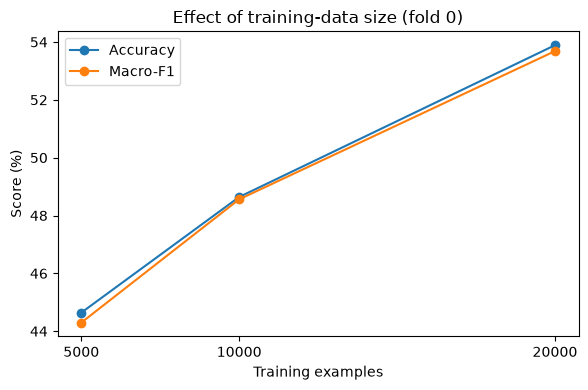

In [27]:
data_size_specs = {
    5_000: PART2_ROOT / "extra-fold0" / "lstm-inf-n5000" / "fold_scores.csv",
    10_000: PART2_ROOT / "extra-fold0" / "lstm-inf-n10000" / "fold_scores.csv",
    20_000: PART2_ROOT / "extra-fold0" / "lstm-inf-n20000" / "fold_scores.csv",
}

data_size_rows = []
for train_examples, path in data_size_specs.items():
    scores = pd.read_csv(path)
    data_size_rows.append({
        "training_examples": train_examples,
        "accuracy": scores["accuracy"].mean(),
        "macro_f1": scores["macro_f1"].mean(),
        "folds": len(scores),
    })

data_size_results = pd.DataFrame(data_size_rows).sort_values("training_examples")
data_size_results.to_csv(OUTPUT_DIR / "lstm_infersent_data_size.csv", index=False)
display(data_size_results.assign(
    accuracy=lambda frame: (100 * frame["accuracy"]).round(2),
    macro_f1=lambda frame: (100 * frame["macro_f1"]).round(2),
))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(data_size_results["training_examples"], 100 * data_size_results["accuracy"], marker="o", label="Accuracy")
ax.plot(data_size_results["training_examples"], 100 * data_size_results["macro_f1"], marker="o", label="Macro-F1")
ax.set_xlabel("Training examples")
ax.set_ylabel("Score (%)")
ax.set_title("Effect of training-data size (fold 0)")
ax.set_xticks(data_size_results["training_examples"])
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "lstm_infersent_data_size.png", dpi=160)
plt.show()

## 2.2 Learning rate

Fold-0 experiments with LSTM + InferSent and frozen GloVe; all other recorded settings are fixed.


In [28]:
learning_rate_specs = {
    3e-3: PART2_ROOT / "extra-fold0" / "lstm-inf-lr3e-3" / "fold_scores.csv",
    3e-4: PART2_ROOT / "extra-fold0" / "lstm-inf-lr3e-4" / "fold_scores.csv",
}

learning_rate_rows = []
for learning_rate, path in learning_rate_specs.items():
    scores = pd.read_csv(path)
    learning_rate_rows.append({
        "learning_rate": learning_rate,
        "accuracy": scores["accuracy"].mean(),
        "macro_f1": scores["macro_f1"].mean(),
        "folds": len(scores),
    })

learning_rate_results = pd.DataFrame(learning_rate_rows).sort_values("learning_rate", ascending=False)
learning_rate_results.to_csv(OUTPUT_DIR / "lstm_infersent_learning_rate.csv", index=False)
display(learning_rate_results.assign(
    accuracy=lambda frame: (100 * frame["accuracy"]).round(2),
    macro_f1=lambda frame: (100 * frame["macro_f1"]).round(2),
))

,learning_rate,accuracy,macro_f1,folds
0,0.0030,54.40,54.36,1
1,0.0003,55.14,55.07,1


## 2.3 Fold and seed variation

Fold variation uses the five folds; seed variation averages the folds for seeds 0, 100 and 200.


In [29]:
variation_specs = {
    "Pooling + InferSent": "pool-frozen-infersent",
    "LSTM + InferSent": "lstm-frozen-h50-infersent",
}
seeds = [0, 100, 200]

fold_variation_rows = []
seed_variation_rows = []
for display_name, run_name in variation_specs.items():
    seed_scores = []
    for seed in seeds:
        path = PART2_ROOT / "final" / run_name / f"seed-{seed}" / "fold_scores.csv"
        scores = pd.read_csv(path)
        seed_accuracy = scores["accuracy"].mean()
        seed_scores.append(seed_accuracy)
        if seed == 0:
            fold_variation_rows.append({
                "Model": display_name,
                "Accuracy mean": seed_accuracy,
                "Accuracy SD across folds": scores["accuracy"].std(),
                "Macro-F1 mean": scores["macro_f1"].mean(),
                "Macro-F1 SD across folds": scores["macro_f1"].std(),
            })
        seed_variation_rows.append({
            "Model": display_name,
            "seed": seed,
            "Accuracy mean across folds": seed_accuracy,
            "Macro-F1 mean across folds": scores["macro_f1"].mean(),
        })

fold_variation = pd.DataFrame(fold_variation_rows)
seed_variation = pd.DataFrame(seed_variation_rows)
seed_summary = seed_variation.groupby("Model").agg(
    accuracy_min=("Accuracy mean across folds", "min"),
    accuracy_max=("Accuracy mean across folds", "max"),
    accuracy_sd_across_seeds=("Accuracy mean across folds", "std"),
    macro_f1_min=("Macro-F1 mean across folds", "min"),
    macro_f1_max=("Macro-F1 mean across folds", "max"),
).reset_index()
fold_variation.to_csv(OUTPUT_DIR / "fold_variation_main_models.csv", index=False)
seed_variation.to_csv(OUTPUT_DIR / "seed_variation_main_models.csv", index=False)
seed_summary.to_csv(OUTPUT_DIR / "seed_variation_summary_main_models.csv", index=False)

print("Fold variation (seed 0):")
display(fold_variation.assign(**{
    "Accuracy": lambda frame: frame["Accuracy mean"].mul(100).round(2).astype(str) + " ± " + frame["Accuracy SD across folds"].mul(100).round(2).astype(str),
    "Macro-F1": lambda frame: frame["Macro-F1 mean"].mul(100).round(2).astype(str) + " ± " + frame["Macro-F1 SD across folds"].mul(100).round(2).astype(str),
})[["Model", "Accuracy", "Macro-F1"]])

print("Seed variation (mean across folds):")
display(seed_summary.assign(**{
    "Accuracy range": lambda frame: frame["accuracy_min"].mul(100).round(2).astype(str) + "–" + frame["accuracy_max"].mul(100).round(2).astype(str),
})[["Model", "Accuracy range", "accuracy_sd_across_seeds"]])

Fold variation (seed 0):


,Model,Accuracy,Macro-F1
0,Pooling + InferSent,48.51 ± 0.83,47.6 ± 1.62
1,LSTM + InferSent,57.59 ± 0.55,57.56 ± 0.61


Seed variation (mean across folds):


,Model,Accuracy range,accuracy_sd_across_seeds
0,LSTM + InferSent,57.39–57.72,0.001674
1,Pooling + InferSent,48.51–48.84,0.001849


## 2.4 Overfitting and embedding setting

The learning curves show the final LSTM + InferSent model on fold 0; the final reported models use frozen 50-dimensional GloVe.


,final_train_accuracy,final_validation_accuracy,best_validation_accuracy,best_validation_epoch,final_accuracy_gap
0,66.16,56.78,57.28,1000,9.38


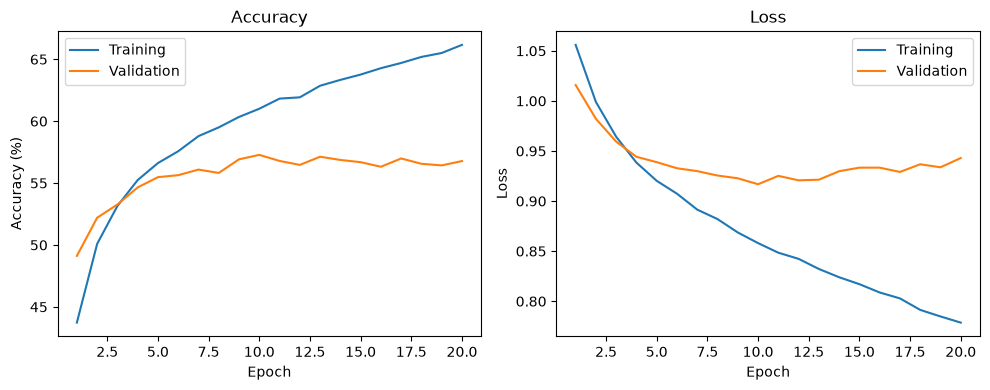

In [30]:
import json
history_path = (PART2_ROOT / "final" / "lstm-frozen-h50-infersent" / "seed-0" / "lstm" / "fold-0" / "model.history.json")
history = pd.DataFrame(json.loads(history_path.read_text()))
history["epoch"] = range(1, len(history) + 1)
history["train_accuracy"] = history["train_metrics"].map(lambda metrics: metrics["accuracy"])
history["val_accuracy"] = history["val_metrics"].map(lambda metrics: metrics["accuracy"])
history["train_loss"] = history["train_metrics"].map(lambda metrics: metrics["loss"])
history["val_loss"] = history["val_metrics"].map(lambda metrics: metrics["loss"])

overfitting_summary = pd.DataFrame([{
    "final_train_accuracy": history["train_accuracy"].iloc[-1],
    "final_validation_accuracy": history["val_accuracy"].iloc[-1],
    "best_validation_accuracy": history["val_accuracy"].max(),
    "best_validation_epoch": history.loc[history["val_accuracy"].idxmax(), "epoch"],
    "final_accuracy_gap": history["train_accuracy"].iloc[-1] - history["val_accuracy"].iloc[-1],
}])
overfitting_summary.to_csv(OUTPUT_DIR / "lstm_infersent_overfitting_summary.csv", index=False)
display(overfitting_summary.mul(100).round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["epoch"], 100 * history["train_accuracy"], label="Training")
axes[0].plot(history["epoch"], 100 * history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[1].plot(history["epoch"], history["train_loss"], label="Training")
axes[1].plot(history["epoch"], history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
for axis in axes:
    axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "lstm_infersent_learning_curves.png", dpi=160)
plt.show()

## 3. Comparison with Project 1

Predictions are matched on fold, pair text and gold label so that both models are evaluated on the same validation occurrences.


In [31]:
overlap_frames = []
for fold_id in sorted(folds):
    path = (PART1_ROOT / 'experiments' / 'mnli-n50000-seed0' /
            'logistic_overlap' / f'fold-{fold_id}' / 'predictions.csv')
    if not path.is_file():
        raise FileNotFoundError(path)
    predictions = pd.read_csv(path)
    validation = fold_validation_rows(fold_id)
    if len(predictions) != len(validation):
        raise RuntimeError(f'Project 1/text mismatch in fold {fold_id}')
    predictions = predictions.copy()
    predictions['fold'] = fold_id
    predictions['premise'] = validation['premise'][:]
    predictions['hypothesis'] = validation['hypothesis'][:]
    predictions['pair_key'] = predictions.apply(pair_key, axis=1)
    predictions['overlap_wrong'] = predictions['gold_label'] != predictions['prediction']
    overlap_frames.append(predictions)

overlap = pd.concat(overlap_frames, ignore_index=True)

lstm_small = seed0[['pairID','pair_key','fold','premise','hypothesis','genre','gold_label','prediction','lstm_wrong']].rename(columns={'prediction':'lstm_prediction'})
overlap_small = overlap[['pairID','pair_key','fold','gold_label','prediction','overlap_wrong']].rename(columns={'prediction':'overlap_prediction'})
comparison = lstm_small.merge(overlap_small, on=['pairID','pair_key','fold','gold_label'], how='inner')

comparison['comparison'] = np.select([
    comparison['lstm_wrong'] & ~comparison['overlap_wrong'],
    ~comparison['lstm_wrong'] & comparison['overlap_wrong'],
    comparison['lstm_wrong'] & comparison['overlap_wrong'],
], ['lstm_wrong_overlap_correct','lstm_correct_overlap_wrong','both_wrong'], default='both_correct')
comparison_counts = comparison['comparison'].value_counts().rename_axis('comparison').reset_index(name='n')
comparison_counts.to_csv(OUTPUT_DIR / 'lstm_overlap_comparison_counts_seed0.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'lstm_overlap_comparison_seed0.csv', index=False)
comparison_counts

,comparison,n
0,both_correct,20786
1,both_wrong,12374
2,lstm_wrong_overlap_correct,8833
3,lstm_correct_overlap_wrong,8022


## 4. Error analysis

The following slices compare LSTM + InferSent with Project 1 overlap features on matched examples. Antonym cues use a small predefined lexicon and should be interpreted as exploratory.


In [32]:
def get_tokens(text):
    tokenizer = BasicTokenizer(
        lowercase=True, remove_punct=False, remove_stopwords=False
    )
    return tokenizer.tokens(str(text))


In [33]:
ANTONYM_PAIRS = {
    ("good", "bad"), ("big", "small"), ("large", "small"), ("high", "low"),
    ("old", "young"), ("new", "old"), ("true", "false"), ("right", "wrong"),
    ("open", "closed"), ("alive", "dead"), ("agree", "disagree"),
    ("more", "less"), ("all", "none"), ("always", "never"),
    ("before", "after"), ("inside", "outside"), ("up", "down"),
    ("increase", "decrease"), ("win", "lose"), ("enter", "leave"),
}

def antonym_pairs_between(premise, hypothesis):
    premise_tokens = set(get_tokens(premise))
    hypothesis_tokens = set(get_tokens(hypothesis))
    found = []
    for first, second in ANTONYM_PAIRS:
        if (first in premise_tokens and second in hypothesis_tokens) or (
            second in premise_tokens and first in hypothesis_tokens
        ):
            found.append(f"{first}/{second}")
    return found

feature_comparison = comparison.copy()
feature_comparison["premise_tokens"] = feature_comparison["premise"].map(get_tokens)
feature_comparison["hypothesis_tokens"] = feature_comparison["hypothesis"].map(get_tokens)
feature_comparison["has_negation"] = feature_comparison.apply(
    lambda row: any(token in NEGATION_TOKENS for token in row["premise_tokens"] + row["hypothesis_tokens"]), axis=1
)
feature_comparison["antonym_pairs"] = feature_comparison.apply(
    lambda row: antonym_pairs_between(row["premise"], row["hypothesis"]), axis=1
)
feature_comparison["has_antonym_cue"] = feature_comparison["antonym_pairs"].map(bool)

feature_rows = []
for feature in ["has_negation", "has_antonym_cue"]:
    for value, group in feature_comparison.groupby(feature, sort=True):
        feature_rows.append({
            "feature": feature,
            "contains_feature": value,
            "n": len(group),
            "lstm_accuracy": 1 - group["lstm_wrong"].mean(),
            "overlap_accuracy": 1 - group["overlap_wrong"].mean(),
            "lstm_error_rate": group["lstm_wrong"].mean(),
            "overlap_error_rate": group["overlap_wrong"].mean(),
            "lstm_minus_overlap_accuracy": group["lstm_wrong"].mean() * -1 + group["overlap_wrong"].mean() * 1,
        })

feature_comparison_summary = pd.DataFrame(feature_rows)
feature_comparison_summary.to_csv(OUTPUT_DIR / "paired_error_features_lstm_vs_overlap.csv", index=False)
display(feature_comparison_summary.assign(**{
    "LSTM accuracy": lambda frame: (100 * frame["lstm_accuracy"]).round(2),
    "Overlap accuracy": lambda frame: (100 * frame["overlap_accuracy"]).round(2),
})[["feature", "contains_feature", "n", "LSTM accuracy", "Overlap accuracy", "lstm_minus_overlap_accuracy"]])

antonym_examples = feature_comparison[feature_comparison["has_antonym_cue"]].copy()
antonym_examples["antonym_pairs"] = antonym_examples["antonym_pairs"].map(", ".join)
antonym_examples[["premise", "hypothesis", "gold_label", "lstm_prediction", "overlap_prediction", "antonym_pairs"]].to_csv(
    OUTPUT_DIR / "paired_antonym_cue_examples.csv", index=False
)


,feature,contains_feature,n,LSTM accuracy,Overlap accuracy,lstm_minus_overlap_accuracy
0,has_negation,False,33157,55.31,58.37,-0.030642
1,has_negation,True,16858,62.10,60.89,0.012160
2,has_antonym_cue,False,49415,57.70,59.29,-0.015825
3,has_antonym_cue,True,600,49.00,53.83,-0.048333


### Sentence, genre and label slices


In [34]:
paired_slices = feature_comparison.copy()
paired_slices["pair_length"] = paired_slices["premise_tokens"].map(len) + paired_slices["hypothesis_tokens"].map(len)
paired_slices["length_bin"] = pd.cut(
    paired_slices["pair_length"], bins=[0, 20, 30, 40, 500], labels=["<=20", "21-30", "31-40", ">40"]
)
paired_slices["lexical_overlap"] = paired_slices.apply(
    lambda row: len(set(row["premise_tokens"]) & set(row["hypothesis_tokens"])) /
    len(set(row["premise_tokens"]) | set(row["hypothesis_tokens"]))
    if set(row["premise_tokens"]) | set(row["hypothesis_tokens"]) else 0.0, axis=1
)
paired_slices["overlap_bin"] = pd.cut(
    paired_slices["lexical_overlap"], bins=[-0.001, .25, .50, .75, 1.001],
    labels=["low", "medium", "high", "very_high"]
)

paired_slice_rows = []
for feature in ["length_bin", "overlap_bin", "genre", "gold_label", "fold"]:
    for value, group in paired_slices.groupby(feature, observed=True, sort=True):
        paired_slice_rows.append({
            "feature": feature,
            "value": value,
            "n": len(group),
            "lstm_accuracy": 1 - group["lstm_wrong"].mean(),
            "overlap_accuracy": 1 - group["overlap_wrong"].mean(),
            "lstm_error_rate": group["lstm_wrong"].mean(),
            "overlap_error_rate": group["overlap_wrong"].mean(),
            "lstm_minus_overlap_accuracy": group["overlap_wrong"].mean() - group["lstm_wrong"].mean(),
        })

paired_slice_summary = pd.DataFrame(paired_slice_rows)
paired_slice_summary.to_csv(OUTPUT_DIR / "paired_error_slices_lstm_vs_overlap.csv", index=False)
display(paired_slice_summary.assign(**{
    "LSTM accuracy": lambda frame: (100 * frame["lstm_accuracy"]).round(2),
    "Overlap accuracy": lambda frame: (100 * frame["overlap_accuracy"]).round(2),
})[["feature", "value", "n", "LSTM accuracy", "Overlap accuracy", "lstm_minus_overlap_accuracy"]])

disagreement_summary = (comparison["comparison"].value_counts()
    .rename_axis("comparison").reset_index(name="n"))
disagreement_summary["fraction"] = disagreement_summary["n"] / disagreement_summary["n"].sum()
disagreement_summary.to_csv(OUTPUT_DIR / "model_disagreement_summary.csv", index=False)
display(disagreement_summary.assign(fraction=lambda frame: (100 * frame["fraction"]).round(2)))

,feature,value,n,LSTM accuracy,Overlap accuracy,lstm_minus_overlap_accuracy
0,length_bin,<=20,11351,60.71,57.92,0.027839
1,length_bin,21-30,12832,59.18,60.25,-0.010676
2,length_bin,31-40,11721,56.74,59.82,-0.030714
3,length_bin,>40,14111,54.37,58.83,-0.044646
4,overlap_bin,low,28953,56.12,58.18,-0.020620
5,overlap_bin,medium,17404,57.52,59.07,-0.015514
6,overlap_bin,high,3100,68.42,66.87,0.015484
7,overlap_bin,very_high,558,76.88,75.45,0.014337
8,genre,fiction,10169,57.80,56.84,0.009637
9,genre,government,9957,59.31,61.39,-0.020890


,comparison,n,fraction
0,both_correct,20786,41.56
1,both_wrong,12374,24.74
2,lstm_wrong_overlap_correct,8833,17.66
3,lstm_correct_overlap_wrong,8022,16.04


## 5. Main conclusions

- LSTM + InferSent is the strongest Project 2 model, but remains below the Project 1 overlap baseline.
- The LSTM improves over mean pooling, and InferSent improves over concatenation.
- Final training accuracy is higher than validation accuracy, indicating overfitting.
- The LSTM is stronger on short pairs and contradiction, while Project 1 is stronger on longer pairs and entailment.
- Both models are less accurate on detected antonym-cue pairs; the cue-based result is exploratory.
